starmap_full_panel: 43,341 cells, 1,015 total genes, median expressed per cell = 104
  → Saved /nfs/team361/sb75/stjepa-reproducibility/artifacts/data/expressed_genes_starmap_full_panel.svg


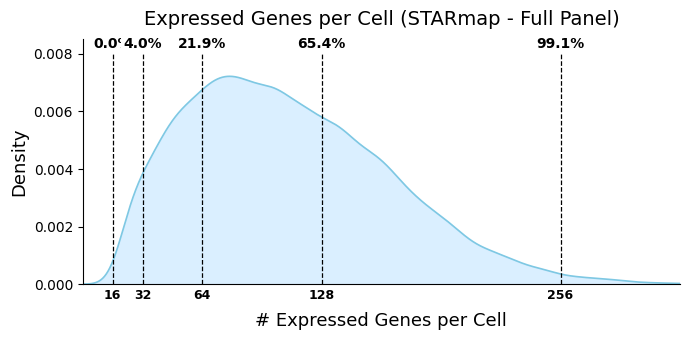

merfish_full_panel: 49,179 cells, 1,085 total genes, median expressed per cell = 71
  → Saved /nfs/team361/sb75/stjepa-reproducibility/artifacts/data/expressed_genes_merfish_full_panel.svg


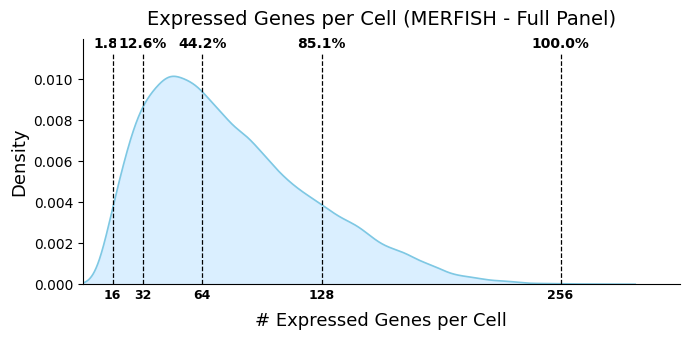

starmap_shared_panel: 42,136 cells, 431 total genes, median expressed per cell = 40
  → Saved /nfs/team361/sb75/stjepa-reproducibility/artifacts/data/expressed_genes_starmap_shared_panel.svg


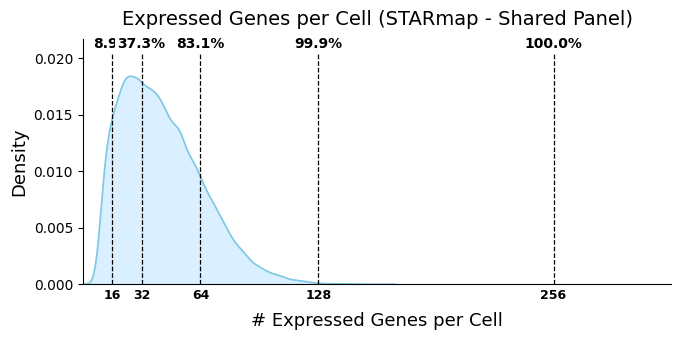

merfish_shared_panel: 44,686 cells, 431 total genes, median expressed per cell = 28
  → Saved /nfs/team361/sb75/stjepa-reproducibility/artifacts/data/expressed_genes_merfish_shared_panel.svg


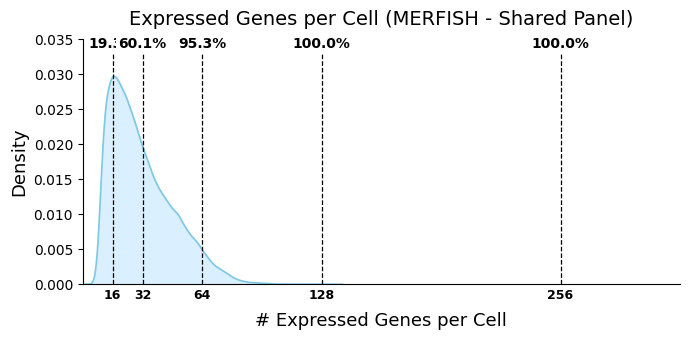

In [4]:
# %% [markdown]
# # Expressed Genes per Cell – Density Plot with Coverage Thresholds

# %% Configuration
import numpy as np
import matplotlib.pyplot as plt
import scanpy as sc
from scipy.stats import gaussian_kde
from pathlib import Path

DATA_DIR_FULL = Path("/nfs/team361/sb75/DATASETS/silver/mmb0-1b_smb1-1b_2p")
DATA_DIR_SHARED = Path("/nfs/team361/sb75/DATASETS/silver/mmb0-1b_smb1-1b_1p")

FILES = {
    # ── Full Panel ──
    "starmap_full_panel": {
        "path": DATA_DIR_FULL / "harmonised_starmap_plus_mouse_cns_batch15.h5ad",
        "title": "Expressed Genes per Cell (STARmap - Full Panel)",
    },
    "merfish_full_panel": {
        "path": DATA_DIR_FULL / "harmonised_merfish_mouse_brain_239-batch_batch82.h5ad",
        "title": "Expressed Genes per Cell (MERFISH - Full Panel)",
    },
    # ── Shared Panel ──
    "starmap_shared_panel": {
        "path": DATA_DIR_SHARED / "harmonised_starmap_plus_mouse_cns_batch15_shared_genes.h5ad",
        "title": "Expressed Genes per Cell (STARmap - Shared Panel)",
    },
    "merfish_shared_panel": {
        "path": DATA_DIR_SHARED / "harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes.h5ad",
        "title": "Expressed Genes per Cell (MERFISH - Shared Panel)",
    },
}

THRESHOLDS = [16, 32, 64, 128, 256]
HIGHLIGHT_THRESHOLD = None

OUT_DIR = Path("/nfs/team361/sb75/stjepa-reproducibility/artifacts/data")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Ensure text is editable in SVGs (not converted to paths)
plt.rcParams["svg.fonttype"] = "none"


# %% Plotting function
def plot_expressed_genes(adata, name, title=None, savepath=None, thresholds=THRESHOLDS, highlight=HIGHLIGHT_THRESHOLD):
    """Density plot of expressed genes per cell with threshold coverage lines."""

    # ── Get gene counts per cell ──────────────────────────────────────────
    if "n_genes_by_counts" in adata.obs.columns:
        n_genes = adata.obs["n_genes_by_counts"].values.astype(float)
    elif "n_genes" in adata.obs.columns:
        n_genes = adata.obs["n_genes"].values.astype(float)
    else:
        # backed mode: read in chunks to avoid loading everything at once
        CHUNK = 50_000
        n = adata.n_obs
        parts = []
        for start in range(0, n, CHUNK):
            end = min(start + CHUNK, n)
            chunk = adata.X[start:end]
            if hasattr(chunk, "toarray"):
                chunk = chunk.toarray()
            parts.append((np.asarray(chunk) > 0).sum(axis=1))
        n_genes = np.concatenate(parts).astype(float)

    n_cells = len(n_genes)
    n_total_genes = adata.n_vars
    print(f"{name}: {n_cells:,} cells, {n_total_genes:,} total genes, median expressed per cell = {np.median(n_genes):.0f}")

    # ── KDE ───────────────────────────────────────────────────────────────
    xs = np.linspace(0, n_genes.max() + 20, 2000)
    density = gaussian_kde(n_genes, bw_method="scott")(xs)

    # ── Figure ────────────────────────────────────────────────────────────
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.fill_between(xs, density, color="#D6EEFF", alpha=0.9)
    ax.plot(xs, density, color="#7EC8E3", linewidth=1.2)

    yhi = density.max()
    ax.set_ylim(0, yhi * 1.18)

    for t in thresholds:
        pct = np.mean(n_genes <= t) * 100
        is_hl = (t == highlight)
        col = "red" if is_hl else "black"

        ax.axvline(t, color=col, linestyle="--", linewidth=1.2 if is_hl else 0.9, zorder=3)
        # percentage label: centered on the line, above the plot area
        ax.text(t, yhi * 1.12, f"{pct:.1f}%",
                ha="center", va="bottom", fontsize=10, fontweight="bold", color=col,
                bbox=dict(facecolor="white", edgecolor="none", pad=1.5))
        # threshold tick label: centered on the line, just below the axis
        ax.text(t, -0.02, str(t),
                ha="center", va="top", fontsize=9, fontweight="bold", color=col,
                transform=ax.get_xaxis_transform(),
                bbox=dict(facecolor="white", edgecolor="none", pad=1.5))

    ax.set_xticks([])
    ax.set_xlim(0, 320)
    ax.set_xlabel("# Expressed Genes per Cell", fontsize=13, labelpad=20)
    ax.set_ylabel("Density", fontsize=13)
    ax.set_title(title or f"Expressed Genes per Cell ({name})", fontsize=14, pad=10)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    fig.tight_layout()
    if savepath:
        fig.savefig(savepath, format="svg", bbox_inches="tight")
        print(f"  → Saved {savepath}")
    plt.show()


# %% Load & plot
for name, info in FILES.items():
    adata = sc.read_h5ad(str(info["path"]), backed="r")
    svg_path = OUT_DIR / f"expressed_genes_{name}.svg"
    plot_expressed_genes(adata, name, title=info["title"], savepath=svg_path)